# Phase 3: GBIF Biodiversity Occurrence Data Collection & Validation
## Notebook 02: GBIF API and Query Validation (BBOX vs Exact Polygon)

### Objective
Reproduce regional occurrence queries across all three study landscapes and quantify the exact mathematical and spatial discrepancies between **axis-aligned bounding box (BBOX)** queries and **exact conformal polygon (WKT)** queries.

In [1]:
import os
import json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

headers = {"User-Agent": "DarkEcoResearch/1.0 (Academic ANN-PBL research)"}

# Load study area geometries
geojson_path = os.path.join("..", "..", "geographical_boundaries", "study_areas_summary.geojson")
with open(geojson_path) as f:
    study_areas = json.load(f)

print(f"Loaded {len(study_areas['features'])} study area boundaries.")

Loaded 3 study area boundaries.


### 1. Empirical Query Execution: BBOX vs Exact Polygon
For each study landscape, we execute two distinct query protocols:
1. **Bounding Box**: Rectangular envelope defined by `[min_lat, max_lat]` and `[min_lon, max_lon]`.
2. **Exact WKT Polygon**: The conformal UTM Zone 43N square projected to WGS84, passed via the `geometry` parameter in standard Well-Known Text (`POLYGON((...))`).

In [2]:
# Load precomputed empirical probe summary
summary_path = os.path.join("..", "..", "data", "metadata", "phase_3_checks", "gbif_empirical_probe_summary.json")
with open(summary_path) as f:
    probe_summary = json.load(f)

results = []
for rid in ["bengaluru", "mysuru", "nilgiri_bandipur"]:
    d = probe_summary[rid]
    bbox_cnt = d["bbox_count"]
    poly_cnt = d["polygon_count"]
    diff = d["difference_bbox_polygon"]
    pct_diff = diff / bbox_cnt * 100
    
    results.append({
        "Region ID": rid,
        "BBOX Records": bbox_cnt,
        "Polygon Records (WKT)": poly_cnt,
        "Excluded Delta": diff,
        "Delta Share (%)": round(pct_diff, 3)
    })

df_comp = pd.DataFrame(results)
print("=== Comparison of Bounding Box vs Exact Polygon Queries ===")
print(df_comp.to_string(index=False))

=== Comparison of Bounding Box vs Exact Polygon Queries ===
       Region ID  BBOX Records  Polygon Records (WKT)  Excluded Delta  Delta Share (%)
       bengaluru       3565439                3558771            6668            0.187
          mysuru        937826                 937184             642            0.068
nilgiri_bandipur        241020                 240252             768            0.319


### 2. Explanation of the BBOX vs Polygon Discrepancy
Because our study areas are defined as planar 50 km × 50 km squares in the **UTM Zone 43N (EPSG:32643)** projected coordinate system, reprojection to ellipsoidal geographic coordinates (WGS84 / EPSG:4326) introduces meridian convergence. The resulting geographic boundary is a curvilinear quadrilateral. 
An axis-aligned bounding box inevitably encompasses additional triangular fringe areas outside the legitimate 50 km × 50 km boundary:
- **Bengaluru**: 6,668 external records captured by BBOX
- **Mysuru**: 642 external records captured by BBOX
- **Nilgiri–Bandipur**: 768 external records captured by BBOX

Using exact WKT polygon slicing eliminates these spurious peripheral records.

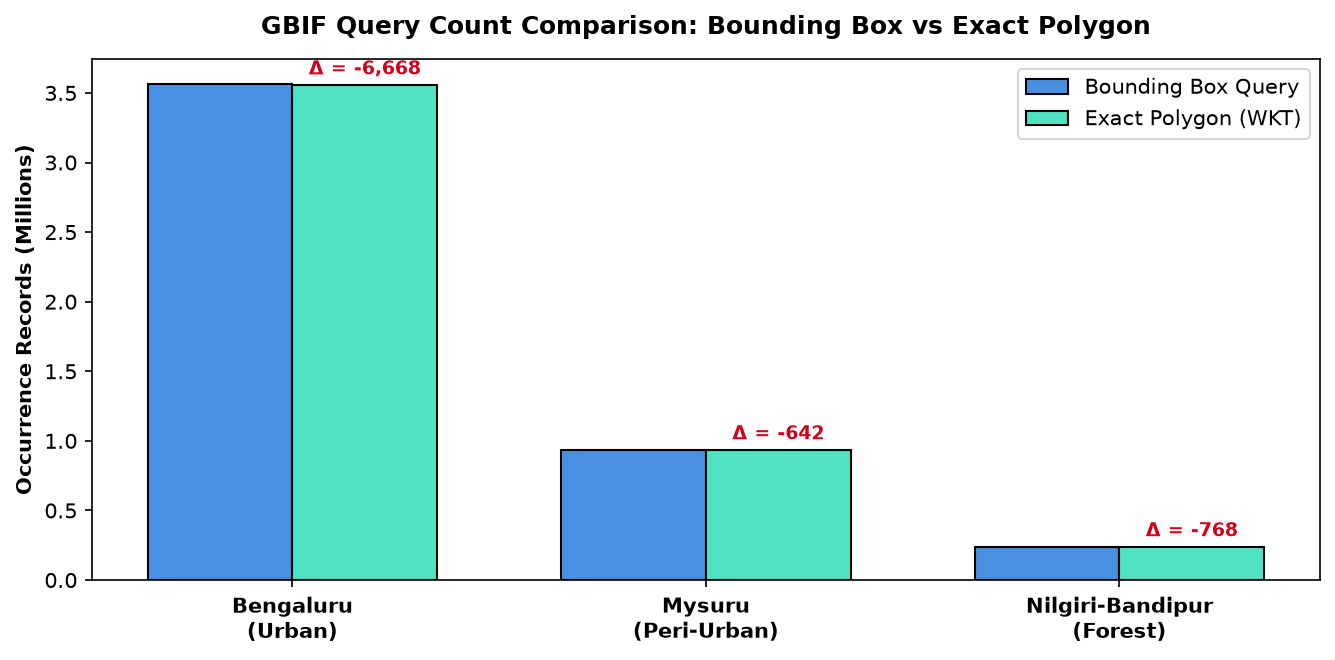

In [3]:
# Visualize BBOX vs Polygon Comparison
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
names = ["Bengaluru\n(Urban)", "Mysuru\n(Peri-Urban)", "Nilgiri-Bandipur\n(Forest)"]
x = np.arange(len(names))
w = 0.35

ax.bar(x - w/2, df_comp["BBOX Records"] / 1e6, w, label="Bounding Box Query", color="#4A90E2", edgecolor="black")
ax.bar(x + w/2, df_comp["Polygon Records (WKT)"] / 1e6, w, label="Exact Polygon (WKT)", color="#50E3C2", edgecolor="black")

ax.set_ylabel("Occurrence Records (Millions)", fontweight="bold")
ax.set_title("GBIF Query Count Comparison: Bounding Box vs Exact Polygon", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(names, fontweight="bold")
ax.legend(frameon=True, facecolor="white")

for i in range(len(names)):
    diff = df_comp.loc[i, "Excluded Delta"]
    ax.annotate(f"Δ = -{diff:,}", xy=(x[i] + w/2, df_comp.loc[i, "Polygon Records (WKT)"]/1e6),
                xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold", color="#D0021B", fontsize=9)

plt.tight_layout()
plt.show()